In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv("../data/allocated/student_restaurants_3312605.csv")
df

,record_id,title,subzone,cuisine,type,cost,lat,lng,coordinate_quality,rating_number_historical
0,9e6e1962c5889e46,Lid & Jar,Rhodes,"[""Modern Australian"", ""Cafe""]","[""Café""]",45.0,-33.831843,151.086170,within_screening_box,3.4
1,31fbcdd01c3ce028,Billy's Kitchen at Botany Golf Club,Botany Bay,"[""Asian"", ""Bar Food""]","[""Casual Dining"", ""Bar""]",50.0,-33.958560,151.207672,within_screening_box,3.2
2,9d70f4c9b5fc9455,JB's on Canterbury,Dulwich Hill,"[""Salad"", ""Sandwich"", ""Burger"", ""Coffee and Tea""]","[""Café""]",40.0,-33.904198,151.141386,within_screening_box,2.7
3,37813654843a9df3,Sienna Cafe,Surry Hills,"[""Cafe""]","[""Café""]",25.0,-33.885416,151.207945,within_screening_box,NaN
4,a6637650ab9821e1,Flame 'n' Chicken,Brookvale,"[""Burger"", ""Fast Food""]","[""Food Court""]",35.0,-33.756605,151.281530,within_screening_box,NaN
...,...,...,...,...,...,...,...,...,...,...
2995,d84143321f9e1ddf,Golden Rose Chinese Restaurant,Moorebank,"[""Chinese""]","[""Casual Dining""]",40.0,-33.932906,150.949682,within_screening_box,3.2
2996,fc44981f694cbd68,Local Bean @ Knightsbridge,"Knightsbridge Shopping Centre, The Hills","[""Cafe""]","[""Café""]",40.0,-33.713075,150.994107,within_screening_box,2.5
2997,79a3b3a2b867733a,Cucinetta,Hunters Hill,"[""Italian""]","[""Casual Dining""]",100.0,-33.840597,151.170828,within_screening_box,3.5
2998,92b2c3537b0ede00,Rosé Royale,Potts Point,"[""Bar Food"", ""French""]","[""Wine Bar""]",70.0,-33.874474,151.224052,within_screening_box,3.1


In [ ]:
# Task A1
# Check row and columns, data tyles, missing values
print(f"Row count: {len(df)}")
print(f"Columns: {df.columns.tolist()}")
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())

Row count: 3000
Columns: ['record_id', 'title', 'subzone', 'cuisine', 'type', 'cost', 'lat', 'lng', 'coordinate_quality', 'rating_number_historical']

Data Types:
record_id                       str
title                           str
subzone                         str
cuisine                         str
type                            str
cost                        float64
lat                         float64
lng                         float64
coordinate_quality              str
rating_number_historical    float64
dtype: object

Missing Values:
record_id                     0
title                         0
subzone                       0
cuisine                       0
type                          8
cost                        115
lat                          97
lng                          97
coordinate_quality            0
rating_number_historical    947
dtype: int64


In [16]:
# Check rating bands
missing_rating = df['rating_number_historical'].isna().sum()
below_2_5 = (df['rating_number_historical'] < 2.5).sum()
band_2_5_to_3_4 = ((df['rating_number_historical'] >= 2.5) & (df['rating_number_historical'] <= 3.4)).sum()
band_3_5_to_3_9 = ((df['rating_number_historical'] >= 3.5) & (df['rating_number_historical'] <= 3.9)).sum()
band_4_0_to_4_4 = ((df['rating_number_historical'] >= 4.0) & (df['rating_number_historical'] <= 4.4)).sum()
above_4_5 = (df['rating_number_historical'] >= 4.5).sum()

print(f"Below 2.5: {below_2_5}")
print(f"2.5-3.4: {band_2_5_to_3_4}")
print(f"3.5-3.9: {band_3_5_to_3_9}")
print(f"4.0-4.4: {band_4_0_to_4_4}")
print(f"4.5+: {above_4_5}")
print(f"No rating: {missing_rating}")

Below 2.5: 60
2.5-3.4: 1286
3.5-3.9: 547
4.0-4.4: 145
4.5+: 15
No rating: 947


In [ ]:
# Check duplicates
duplicates = df['title'].value_counts()
duplicates = duplicates[duplicates > 1]
print(f"Restaurants listed more than once: {len(duplicates)}")

Restaurants listed more than once: 8


In [13]:
duplicates

title
Annie's Bakery        2
The Garden            2
Cafe Piccolo          2
Golden Sands          2
Queens Park Pizza     2
The Chocolate Room    2
Royal Hotel           2
Fusion Cafe           2
Name: count, dtype: int64

In [ ]:
# Summary stats
print(df.describe(include='all').to_string())

               record_id           title subzone   cuisine               type         cost          lat          lng    coordinate_quality  rating_number_historical
count               3000            3000    3000      3000               2992  2885.000000  2903.000000  2903.000000                  3000               2053.000000
unique              3000            2992     447       778                 49          NaN          NaN          NaN                     3                       NaN
top     9e6e1962c5889e46  Annie's Bakery     CBD  ["Cafe"]  ["Casual Dining"]          NaN          NaN          NaN  within_screening_box                       NaN
freq                   1               2     135       489               1403          NaN          NaN          NaN                  2903                       NaN
mean                 NaN             NaN     NaN       NaN                NaN    51.720624   -33.861624   151.120730                   NaN                  3.276473
std       

In [ ]:
import geopandas as gpd
from shapely.geometry import Point

# Load GeoJSON data
geo_syd = gpd.read_file("../data/raw/sydney.geojson")

# delete rows in df without lat and long
df_valid = df.dropna(subset=['lat', 'lng']).copy()

# clean names (lowercase and remove ' (NSW)' suffixes)
df_valid['subzone_clean'] = df_valid['subzone'].astype(str).str.strip().str.lower()
geo_syd['SSC_NAME_clean'] = geo_syd['SSC_NAME'].astype(str).str.replace(' (NSW)', '', regex=False).str.strip().str.lower()

# convert csv coordinates into geometric points
geometry = [Point(xy) for xy in zip(df_valid['lng'], df_valid['lat'])]
geo_restaurants = gpd.GeoDataFrame(df_valid, geometry=geometry, crs=geo_syd.crs)

# spatial join, checks which polygon each point falls into
# left join to preserve all restaurants
joined = gpd.sjoin(geo_restaurants, geo_syd, how="left", predicate="intersects")

# Points outside the map (no matching index)
outside_map = joined[joined['index_right'].isna()]

# Points inside the map, but subzone doesn't match GeoJSON SSC_NAME
inside_map = joined[~joined['index_right'].isna()]
mismatches = inside_map[inside_map['subzone_clean'] != inside_map['SSC_NAME_clean']]

print(f"Points outside the map: {len(outside_map)}")
print(f"Points with mismatched subzones: {len(mismatches)}")

Points outside the map: 291
Points with mismatched subzones: 918


Unique cuisine labels count: 114


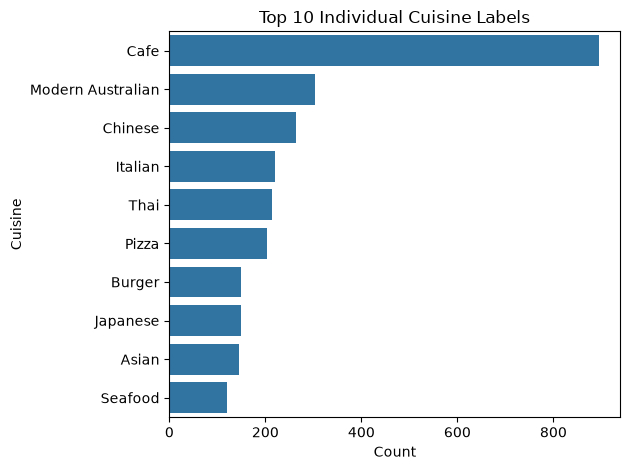

In [93]:
# Q1: How many different cuisine labels are there?
import ast # parsing literal string like "['a', 'b']" to a python list

cuisines_list = []
for c_str in df['cuisine']:
    try:
        c_parsed = ast.literal_eval(c_str)
        if isinstance(c_parsed, list):
            cuisines_list.extend(c_parsed)
        elif isinstance(c_parsed, str):
            cuisines_list.append(c_parsed)
    except:
        pass

unique_cuisines = pd.Series(cuisines_list).unique()
print(f"Unique cuisine labels count: {len(unique_cuisines)}")

plt.figure()
cuisine_counts = pd.Series(cuisines_list).value_counts().head(10)
sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index)
plt.title("Top 10 Individual Cuisine Labels")
plt.xlabel("Count")
plt.ylabel("Cuisine")
plt.tight_layout()

Top 3 subzones:
subzone
CBD            135
Surry Hills     73
Parramatta      65
Name: count, dtype: int64


Text(0, 0.5, 'Number of Restaurants')

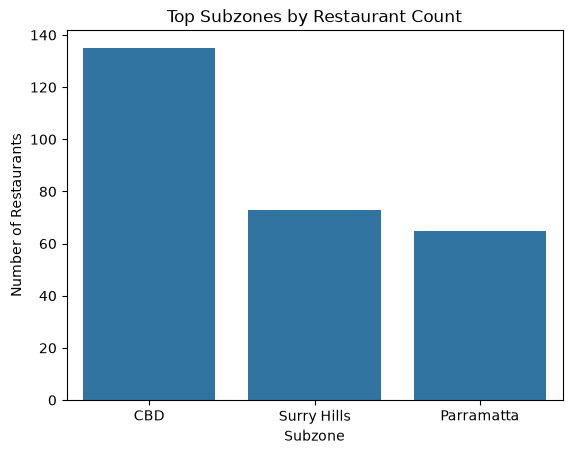

In [101]:
# Q2: Which 3 subzone labels have the most restaurants?
top_subzones = df['subzone'].value_counts().head(3)
print("Top 3 subzones:")
print(top_subzones)

plt.figure()
top_sub_counts = df['subzone'].value_counts().head(3)
sns.barplot(x=top_sub_counts.index, y=top_sub_counts.values)
plt.title("Top Subzones by Restaurant Count")
plt.xlabel("Subzone")
plt.ylabel("Number of Restaurants")


In [70]:
# Q3: Are top-band restaurants (4.5+, 15 records) more expensive than bottom-band ones (below 2.5, 60 records)?
top_band = df[df['rating_number_historical'] >= 4.5]
bottom_band = df[df['rating_number_historical'] < 2.5]
print(f"Top band count: {len(top_band)}, mean cost: {top_band['cost'].mean():.2f}")
print(f"Bottom band count: {len(bottom_band)}, mean cost: {bottom_band['cost'].mean():.2f}")

Top band count: 15, mean cost: 126.33
Bottom band count: 60, mean cost: 57.23


In [74]:
# Q5: Is cost related to the number of cuisine labels?
df['cuisine_count'] = df['cuisine'].apply(lambda x: len(ast.literal_eval(x)))
corr = df['cost'].corr(df['cuisine_count'])
print(f"Correlation between cost and cuisine count: {corr:.3f}")

Correlation between cost and cuisine count: 0.050


Cafes count: 891, Fine dining count: 30


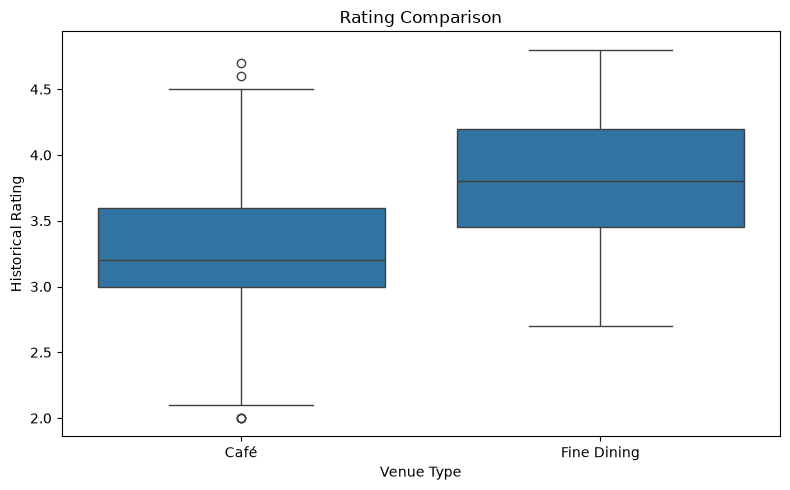

In [ ]:
# Q6: Do cafés and fine-dining venues differ in rating?
def has_type(type_str, target):
    """Parse literal string to list then check if target is in the list"""
    if not isinstance(type_str, str):
        return False
    parsed = ast.literal_eval(type_str)
    if isinstance(parsed, list):
        return target in parsed
    return parsed == target


cafes = df[df['type'].apply(lambda x: has_type(x, 'Café'))]
fine_dining = df[df['type'].apply(lambda x: has_type(x, 'Fine Dining'))]

print(f"Cafes count: {len(cafes)}, Fine dining count: {len(fine_dining)}")

cafe_fine_df = pd.concat([
    cafes.assign(Venue_Type='Café'),
    fine_dining.assign(Venue_Type='Fine Dining')
])

plt.figure(figsize=(8, 5))
sns.boxplot(x='Venue_Type', y='rating_number_historical', data=cafe_fine_df)
plt.title("Rating Comparison")
plt.xlabel("Venue Type")
plt.ylabel("Historical Rating")
plt.tight_layout()